# Deep Armocromia RGB-M — Hierarchical Multi-Task EfficientNet for Platform Readiness

Eksperimen ini dibuat setelah baseline 12-class menunjukkan:

- Official Test Accuracy ≈ **29.28%**
- Macro Recall ≈ **27.00%**
- Macro F1 ≈ **25.54%**
- Top-3 Accuracy ≈ **62.72%**
- Best validation Macro F1 ≈ **40.54%**
- Train accuracy terus naik sampai ±88% sementara validation berhenti di ±40% → **overfitting**

## Tujuan versi ini

Bukan sekadar meningkatkan train accuracy, tetapi membuat pipeline lebih layak untuk platform:

1. Tetap mempertahankan **official test untouched**.
2. Validation dibuat **source-aware** bila official test 100% CelebA.
3. EfficientNet-B0 tetap digunakan agar perbandingan fair.
4. Multi-task learning:
   - main head: **12 joint classes**
   - auxiliary head: **4 seasons**
   - auxiliary head: **6 subtype names**
5. Mild class weighting, bukan oversampling agresif.
6. Partial fine-tuning untuk mengurangi overfitting.
7. Validation-only probability fusion untuk memilih kombinasi output terbaik.
8. Confidence calibration + uncertainty threshold.
9. Platform tidak wajib memaksakan satu rekomendasi bila model tidak yakin:
   - confident → gunakan Top-1
   - uncertain → tampilkan Top-3 / minta foto ulang
10. Menyimpan checkpoint + metadata inference.

> **Catatan penting:** model ini dilatih pada **RGB-M (masked face)**. Untuk platform nyata, foto user harus melalui preprocessing/masking yang konsisten sebelum masuk model. Notebook ini mengevaluasi model pada RGB-M dataset; face parsing user-facing bukan bagian dari eksperimen ini.

## 0. Konfigurasi Eksperimen

Sebelum `Save & Run All`:
- Attach private dataset **Deep Armocromia**
- Buat Kaggle Secret `DEEP_ARMO_PASSWORD`
- Settings → Accelerator → **GPU T4**

In [1]:
# ============================================================
# 0. EXPERIMENT CONFIG
# ============================================================

EXPERIMENT_ID = "E4_HIER_MT"
EXPERIMENT_NAME = "Hierarchical Multi-Task EfficientNet-B0"

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4

# Validation
VAL_FRACTION_OF_CELEBA_POOL = 0.15

# Model
HIDDEN_DIM = 640
DROPOUT = 0.40
UNFREEZE_LAST_N_BLOCKS = 5

# Loss
JOINT_LOSS_WEIGHT = 1.00
SEASON_LOSS_WEIGHT = 0.35
SUBTYPE_LOSS_WEIGHT = 0.25
LABEL_SMOOTHING = 0.03
USE_MILD_CLASS_WEIGHTS = True

# Training
STAGE1_EPOCHS = 3
MAX_FINETUNE_EPOCHS = 24
EARLY_STOPPING_PATIENCE = 6

HEAD_LR_STAGE1 = 8e-4
BACKBONE_LR = 3e-5
HEAD_LR_STAGE2 = 2e-4
WEIGHT_DECAY = 4e-4
GRAD_CLIP = 1.0

# Fusion tuning — validation only
ALPHA_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]  # season influence
BETA_GRID  = [0.0, 0.25, 0.5, 0.75, 1.0]  # subtype influence

# Platform uncertainty
TARGET_SELECTIVE_ACCURACY = 0.60
MIN_SELECTIVE_COVERAGE = 0.15

print(EXPERIMENT_ID, "-", EXPERIMENT_NAME)

E4_HIER_MT - Hierarchical Multi-Task EfficientNet-B0


In [2]:
# ============================================================
# 1. IMPORTS & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import math
import random
import shutil
import hashlib
import subprocess
import warnings
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ImageFile.LOAD_TRUNCATED_IMAGES = False
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Python :", sys.version.split()[0])
print("Torch  :", torch.__version__)
print("CUDA   :", torch.cuda.is_available())

Python : 3.13.15
Torch  : 2.11.0+cu128
CUDA   : True


## 2. Deteksi Dataset dan Extraction RGB-M

Notebook dapat memakai:
- prepared RGB-M dataset bila sudah tersedia, atau
- source private dataset yang masih memiliki `RGB-M.zip`.

Pada mode encrypted source, password hanya diambil dari Kaggle Secret.

In [3]:
# ============================================================
# 2. DETECT DATASET
# ============================================================

KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

assert KAGGLE_INPUT.exists(), "/kaggle/input tidak ditemukan."

annotation_candidates = list(KAGGLE_INPUT.rglob("annotations.csv"))

prepared_matches = []
source_matches = []

for ann in annotation_candidates:
    root = ann.parent

    if (root / "RGB-M").is_dir():
        prepared_matches.append((root, ann))

    if (root / "RGB-M.zip").is_file():
        source_matches.append((root, ann, root / "RGB-M.zip"))

if prepared_matches:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared_matches[0]
    RGBM_ZIP = None

elif source_matches:
    MODE = "ENCRYPTED_SOURCE"
    SOURCE_ROOT, ANNOTATION_PATH, RGBM_ZIP = source_matches[0]
    DATA_ROOT = WORK_PREPARED_ROOT

else:
    raise FileNotFoundError(
        "Tidak menemukan annotations.csv + RGB-M/ atau RGB-M.zip."
    )

print("MODE       :", MODE)
print("ANNOTATION :", ANNOTATION_PATH)

MODE       : ENCRYPTED_SOURCE
ANNOTATION : /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv


In [4]:
# ============================================================
# 3. LOAD ANNOTATIONS
# ============================================================

df = pd.read_csv(ANNOTATION_PATH)

SEASON_COL = "class"
SUBCLASS_COL = "sub_class"
PARTITION_COL = "partition"
MASKED_PATH_COL = "path_rgb_masked"

required_cols = [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
    MASKED_PATH_COL,
    "celeba",
]

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

assert not missing_cols, (
    f"Kolom wajib hilang: {missing_cols}"
)

for col in [
    SEASON_COL,
    SUBCLASS_COL,
    PARTITION_COL,
]:
    df[col] = (
        df[col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

df["joint_label"] = (
    df[SEASON_COL]
    + "_"
    + df[SUBCLASS_COL]
)

# Normalize celeba to bool
if df["celeba"].dtype != bool:
    df["celeba"] = (
        df["celeba"]
        .astype(str)
        .str.lower()
        .map({
            "true": True,
            "1": True,
            "false": False,
            "0": False,
        })
    )

assert df["celeba"].notna().all()

EXPECTED_IMAGES = len(df)

print("Rows          :", len(df))
print("Season        :", df[SEASON_COL].nunique())
print("Subtype names :", df[SUBCLASS_COL].nunique())
print("Joint classes :", df["joint_label"].nunique())
print("Missing       :", int(df[required_cols].isna().sum().sum()))
print("Duplicate row :", int(df.duplicated().sum()))

Rows          : 4920
Season        : 4
Subtype names : 6
Joint classes : 12
Missing       : 0
Duplicate row : 0


In [5]:
# ============================================================
# 4. EXTRACT RGB-M USING KAGGLE SECRET
# ============================================================

IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
}

def count_images(root):
    if not root.exists():
        return 0

    return sum(
        1
        for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

if MODE == "PREPARED_INPUT":
    RGBM_ROOT = DATA_ROOT / "RGB-M"

else:
    WORK_PREPARED_ROOT.mkdir(
        parents=True,
        exist_ok=True,
    )

    RGBM_ROOT = (
        WORK_PREPARED_ROOT
        / "RGB-M"
    )

    if count_images(RGBM_ROOT) != EXPECTED_IMAGES:
        from kaggle_secrets import UserSecretsClient

        try:
            PASSWORD = (
                UserSecretsClient()
                .get_secret(
                    "DEEP_ARMO_PASSWORD"
                )
            )
        except Exception as e:
            raise RuntimeError(
                "Secret DEEP_ARMO_PASSWORD belum tersedia "
                "atau belum diaktifkan untuk notebook."
            ) from e

        if not PASSWORD:
            raise RuntimeError(
                "DEEP_ARMO_PASSWORD kosong."
            )

        print("🔐 Secret berhasil dibaca.")
        print("Extracting RGB-M...")

        unzip_path = shutil.which("unzip")

        if unzip_path:
            result = subprocess.run(
                [
                    unzip_path,
                    "-n",
                    "-P",
                    PASSWORD,
                    str(RGBM_ZIP),
                    "-d",
                    str(WORK_PREPARED_ROOT),
                ],
                stdout=subprocess.DEVNULL,
                stderr=subprocess.PIPE,
                text=True,
            )

            if result.returncode not in (0, 1):
                raise RuntimeError(
                    result.stderr[-3000:]
                )

        else:
            import zipfile

            with zipfile.ZipFile(
                RGBM_ZIP,
                "r",
            ) as z:
                z.extractall(
                    WORK_PREPARED_ROOT,
                    pwd=PASSWORD.encode(
                        "utf-8"
                    ),
                )

        del PASSWORD

    prepared_annotation = (
        WORK_PREPARED_ROOT
        / "annotations.csv"
    )

    if not prepared_annotation.exists():
        shutil.copy2(
            ANNOTATION_PATH,
            prepared_annotation,
        )

    DATA_ROOT = WORK_PREPARED_ROOT
    ANNOTATION_PATH = prepared_annotation

print(
    "RGB-M image count:",
    count_images(RGBM_ROOT)
)

assert (
    count_images(RGBM_ROOT)
    == EXPECTED_IMAGES
)

🔐 Secret berhasil dibaca.
Extracting RGB-M...
RGB-M image count: 4920


## 5. EDA dan Quality Control

Bagian ini fokus pada audit yang relevan untuk modelling:
- distribusi kelas,
- imbalance,
- source/domain `celeba`,
- path validity,
- corrupt image,
- resolution,
- exact duplicate/leakage.

In [6]:
# ============================================================
# 5. LABEL & SOURCE EDA
# ============================================================

print("Season distribution")
display(
    df[SEASON_COL]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

print("\nJoint class distribution")
joint_counts = (
    df["joint_label"]
    .value_counts()
    .sort_index()
)

display(
    joint_counts
    .to_frame("count")
)

imbalance_ratio = (
    joint_counts.max()
    / joint_counts.min()
)

print(
    "\nImbalance ratio:",
    round(
        float(imbalance_ratio),
        3,
    )
)

print("\nOfficial partition")
display(
    df[PARTITION_COL]
    .value_counts()
    .to_frame("count")
)

print("\nSource (CelebA) by official partition")
source_table = pd.crosstab(
    df[PARTITION_COL],
    df["celeba"],
)

display(source_table)

source_pct = (
    pd.crosstab(
        df[PARTITION_COL],
        df["celeba"],
        normalize="index",
    )
    * 100
)

print("\nSource percentage")
display(source_pct.round(2))

Season distribution


,count
class,
autunno,1305
estate,1129
inverno,1305
primavera,1181



Joint class distribution


,count
joint_label,
autunno_deep,557
autunno_soft,391
autunno_warm,357
estate_cool,329
estate_light,382
estate_soft,418
inverno_bright,329
inverno_cool,434
inverno_deep,542



Imbalance ratio: 1.693

Official partition


,count
partition,
train,4008
test,912



Source (CelebA) by official partition


celeba,False,True
partition,,
test,0,912
train,1939,2069



Source percentage


celeba,False,True
partition,,
test,0.00,100.00
train,48.38,51.62


In [7]:
# ============================================================
# 6. PATH RESOLUTION + CORRUPT CHECK
# ============================================================

def resolve_image_path(relative_path):
    p = Path(
        str(relative_path)
        .replace("\\", "/")
        .strip()
    )

    candidates = [
        DATA_ROOT / p,
        DATA_ROOT / "RGB-M" / p,
    ]

    if str(p).startswith("RGB-M/"):
        candidates.append(
            DATA_ROOT
            / Path(
                str(p)[len("RGB-M/"):]
            )
        )

    for candidate in candidates:
        if candidate.is_file():
            return candidate

    return None


df["resolved_path"] = (
    df[MASKED_PATH_COL]
    .apply(resolve_image_path)
)

print(
    "Valid path:",
    df["resolved_path"]
    .notna()
    .sum(),
    "/",
    len(df),
)

corrupt_idx = []
properties = []

for idx, row in df.iterrows():
    path = row["resolved_path"]

    if path is None:
        corrupt_idx.append(idx)
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            properties.append({
                "idx": idx,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
            })

    except Exception:
        corrupt_idx.append(idx)

properties_df = pd.DataFrame(
    properties
)

print(
    "Corrupt / unreadable:",
    len(corrupt_idx)
)

if len(properties_df):
    display(
        properties_df[
            ["width", "height"]
        ].describe()
    )

    print(
        "Image modes:",
        properties_df["mode"]
        .value_counts()
        .to_dict()
    )

Valid path: 4920 / 4920
Corrupt / unreadable: 0


,width,height
count,4920.000000,4920.000000
mean,534.065650,574.292886
std,211.986499,263.275514
min,45.000000,110.000000
25%,512.000000,512.000000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,2903.000000,3725.000000


Image modes: {'RGB': 4920}


In [8]:
# ============================================================
# 7. EXACT DUPLICATE / LEAKAGE AUDIT
# ============================================================

def md5_file(path, chunk_size=1024 * 1024):
    h = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(chunk_size),
            b"",
        ):
            h.update(chunk)

    return h.hexdigest()


valid_df = df[
    df["resolved_path"].notna()
].copy()

if corrupt_idx:
    valid_df = valid_df[
        ~valid_df.index.isin(
            corrupt_idx
        )
    ].copy()

valid_df["md5"] = (
    valid_df["resolved_path"]
    .apply(md5_file)
)

hash_partition_count = (
    valid_df
    .groupby("md5")[
        PARTITION_COL
    ]
    .nunique()
)

cross_split_hashes = (
    hash_partition_count[
        hash_partition_count > 1
    ]
)

print(
    "Exact hash crossing official partitions:",
    len(cross_split_hashes),
)

assert len(
    cross_split_hashes
) == 0, (
    "Official train-test exact duplicate leakage ditemukan."
)

clean_df = valid_df.copy()

print(
    "Clean rows:",
    len(clean_df),
)

Exact hash crossing official partitions: 0
Clean rows: 4920


## 8. Source-Aware Train / Validation Split

Bila official test ternyata 100% CelebA:
- validation diambil **15% dari CelebA pool official train**, bukan 15% dari seluruh train;
- seluruh non-CelebA official train tetap dipakai untuk training;
- official test tetap untouched.

Ini menjaga jumlah CelebA training kira-kira setara dengan split random 85/15, tetapi validation lebih representatif terhadap domain test.

In [9]:
# ============================================================
# 8. SOURCE-AWARE SPLIT
# ============================================================

official_train = clean_df[
    clean_df[PARTITION_COL]
    == "train"
].copy()

test_df = clean_df[
    clean_df[PARTITION_COL]
    == "test"
].copy()

test_is_all_celeba = bool(
    test_df["celeba"].all()
)

print(
    "Official test 100% CelebA:",
    test_is_all_celeba
)

if test_is_all_celeba:
    celeba_pool = official_train[
        official_train["celeba"]
    ].copy()

    non_celeba_pool = official_train[
        ~official_train["celeba"]
    ].copy()

    celeba_train, val_df = (
        train_test_split(
            celeba_pool,
            test_size=VAL_FRACTION_OF_CELEBA_POOL,
            random_state=SEED,
            stratify=celeba_pool[
                "joint_label"
            ],
        )
    )

    train_df = pd.concat(
        [
            celeba_train,
            non_celeba_pool,
        ],
        ignore_index=True,
    )

    train_df = (
        train_df
        .sample(
            frac=1,
            random_state=SEED,
        )
        .reset_index(drop=True)
    )

    val_df = (
        val_df
        .reset_index(drop=True)
    )

else:
    train_df, val_df = (
        train_test_split(
            official_train,
            test_size=0.15,
            random_state=SEED,
            stratify=official_train[
                "joint_label"
            ],
        )
    )

    train_df = train_df.reset_index(
        drop=True
    )
    val_df = val_df.reset_index(
        drop=True
    )

test_df = test_df.reset_index(
    drop=True
)

print("Train :", len(train_df))
print("Val   :", len(val_df))
print("Test  :", len(test_df))

print("\nCelebA percentage:")
print(
    "Train:",
    round(
        train_df["celeba"].mean()
        * 100,
        2,
    ),
)
print(
    "Val  :",
    round(
        val_df["celeba"].mean()
        * 100,
        2,
    ),
)
print(
    "Test :",
    round(
        test_df["celeba"].mean()
        * 100,
        2,
    ),
)

assert (
    train_df["joint_label"]
    .nunique()
    == 12
)

assert (
    val_df["joint_label"]
    .nunique()
    == 12
)

assert (
    test_df["joint_label"]
    .nunique()
    == 12
)

Official test 100% CelebA: True
Train : 3697
Val   : 311
Test  : 912

CelebA percentage:
Train: 47.55
Val  : 100.0
Test : 100.0


In [10]:
# ============================================================
# 9. FINAL SPLIT LEAKAGE CHECK
# ============================================================

train_hashes = set(
    train_df["md5"]
)
val_hashes = set(
    val_df["md5"]
)
test_hashes = set(
    test_df["md5"]
)

assert not (
    train_hashes
    & val_hashes
)

assert not (
    train_hashes
    & test_hashes
)

assert not (
    val_hashes
    & test_hashes
)

print(
    "✅ Train/Val/Test exact-file leakage = 0"
)

✅ Train/Val/Test exact-file leakage = 0


## 10. Encoding: Joint + Season + Subtype

Multi-task learning memakai label yang berasal dari annotation yang sama.  
Output utama tetap **12 joint class** agar tidak menghasilkan kombinasi season-subtype ilegal.

In [11]:
# ============================================================
# 10. LABEL ENCODING
# ============================================================

joint_names = sorted(
    train_df[
        "joint_label"
    ].unique()
)

season_names = sorted(
    train_df[
        SEASON_COL
    ].unique()
)

subtype_names = sorted(
    train_df[
        SUBCLASS_COL
    ].unique()
)

assert len(joint_names) == 12
assert len(season_names) == 4
assert len(subtype_names) == 6

joint2idx = {
    name: i
    for i, name
    in enumerate(joint_names)
}

season2idx = {
    name: i
    for i, name
    in enumerate(season_names)
}

subtype2idx = {
    name: i
    for i, name
    in enumerate(subtype_names)
}

idx2joint = {
    v: k
    for k, v
    in joint2idx.items()
}

joint_to_season_idx = []
joint_to_subtype_idx = []

for joint_name in joint_names:
    season, subtype = (
        joint_name.split(
            "_",
            1,
        )
    )

    joint_to_season_idx.append(
        season2idx[season]
    )

    joint_to_subtype_idx.append(
        subtype2idx[subtype]
    )

for frame in [
    train_df,
    val_df,
    test_df,
]:
    frame["joint_idx"] = (
        frame["joint_label"]
        .map(joint2idx)
    )

    frame["season_idx"] = (
        frame[SEASON_COL]
        .map(season2idx)
    )

    frame["subtype_idx"] = (
        frame[SUBCLASS_COL]
        .map(subtype2idx)
    )

print("Joint   :", joint_names)
print("Season  :", season_names)
print("Subtype :", subtype_names)

Joint   : ['autunno_deep', 'autunno_soft', 'autunno_warm', 'estate_cool', 'estate_light', 'estate_soft', 'inverno_bright', 'inverno_cool', 'inverno_deep', 'primavera_bright', 'primavera_light', 'primavera_warm']
Season  : ['autunno', 'estate', 'inverno', 'primavera']
Subtype : ['bright', 'cool', 'deep', 'light', 'soft', 'warm']


## 11. Preprocessing

Color adalah sinyal penting, jadi versi ini **tidak memakai ColorJitter**.  
Augmentasi dibatasi pada transformasi geometrik ringan.

In [12]:
# ============================================================
# 11. TRANSFORMS
# ============================================================

NORM_MEAN = [
    0.485,
    0.456,
    0.406,
]

NORM_STD = [
    0.229,
    0.224,
    0.225,
]


class PadToSquare:
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, image):
        w, h = image.size
        side = max(w, h)

        left = (
            side - w
        ) // 2
        right = (
            side - w - left
        )

        top = (
            side - h
        ) // 2
        bottom = (
            side - h - top
        )

        return TF.pad(
            image,
            [
                left,
                top,
                right,
                bottom,
            ],
            fill=self.fill,
        )


train_transform = transforms.Compose([
    PadToSquare(fill=0),
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),
    transforms.RandomHorizontalFlip(
        p=0.5
    ),
    transforms.RandomRotation(
        degrees=5,
        fill=0,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

eval_transform = transforms.Compose([
    PadToSquare(fill=0),
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORM_MEAN,
        std=NORM_STD,
    ),
])

print("Transforms ready.")

Transforms ready.


In [13]:
# ============================================================
# 12. DATASET + DATALOADER
# ============================================================

class ArmocromiaMultiTaskDataset(
    Dataset
):
    def __init__(
        self,
        dataframe,
        transform,
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
        )
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(
        self,
        idx,
    ):
        row = self.df.iloc[idx]

        with Image.open(
            row["resolved_path"]
        ) as img:
            img = img.convert("RGB")

        img = self.transform(img)

        return (
            img,
            torch.tensor(
                row["joint_idx"],
                dtype=torch.long,
            ),
            torch.tensor(
                row["season_idx"],
                dtype=torch.long,
            ),
            torch.tensor(
                row["subtype_idx"],
                dtype=torch.long,
            ),
        )


train_ds = (
    ArmocromiaMultiTaskDataset(
        train_df,
        train_transform,
    )
)

val_ds = (
    ArmocromiaMultiTaskDataset(
        val_df,
        eval_transform,
    )
)

test_ds = (
    ArmocromiaMultiTaskDataset(
        test_df,
        eval_transform,
    )
)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
    generator=generator,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=(
        NUM_WORKERS > 0
    ),
)

batch = next(
    iter(train_loader)
)

print(
    "Image batch:",
    batch[0].shape
)
print(
    "Joint labels:",
    batch[1].shape
)

Image batch: torch.Size([32, 3, 224, 224])
Joint labels: torch.Size([32])


## 13. Mild Class Weights

Karena imbalance hanya sekitar 1.69×, weight tidak dibuat agresif.  
Dipakai **square-root inverse frequency** sehingga kelas kecil sedikit dibantu tanpa membuat sampler ganda.

In [14]:
# ============================================================
# 13. MILD CLASS WEIGHTS
# ============================================================

joint_train_counts = (
    train_df[
        "joint_label"
    ]
    .value_counts()
    .reindex(joint_names)
)

if USE_MILD_CLASS_WEIGHTS:
    raw_weights = np.sqrt(
        joint_train_counts.max()
        / joint_train_counts.values
    )

    raw_weights = (
        raw_weights
        / raw_weights.mean()
    )

else:
    raw_weights = np.ones(
        len(joint_names)
    )

joint_class_weights = (
    torch.tensor(
        raw_weights,
        dtype=torch.float32,
    )
)

weight_df = pd.DataFrame({
    "class": joint_names,
    "count": (
        joint_train_counts
        .values
    ),
    "weight": raw_weights,
})

display(weight_df)

,class,count,weight
0,autunno_deep,409,0.860425
1,autunno_soft,292,1.018318
2,autunno_warm,259,1.081247
3,estate_cool,253,1.093993
4,estate_light,289,1.023590
5,estate_soft,334,0.952142
6,inverno_bright,252,1.096161
7,inverno_cool,316,0.978884
8,inverno_deep,385,0.886838
9,primavera_bright,270,1.058992


In [15]:
# ============================================================
# 14. DEVICE CHECK
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

assert DEVICE.type == "cuda", (
    "Aktifkan GPU T4 sebelum training."
)

Device: cuda
GPU: Tesla T4


## 15. Hierarchical Multi-Task EfficientNet-B0

Satu shared feature extractor menghasilkan:
- 12-class joint prediction,
- 4-class season prediction,
- 6-class subtype prediction.

Joint head tetap output utama.

In [16]:
# ============================================================
# 15. MODEL
# ============================================================

class HierarchicalEfficientNet(
    nn.Module
):
    def __init__(
        self,
        num_joint=12,
        num_season=4,
        num_subtype=6,
    ):
        super().__init__()

        weights = (
            EfficientNet_B0_Weights
            .DEFAULT
        )

        base = efficientnet_b0(
            weights=weights
        )

        self.features = (
            base.features
        )

        self.avgpool = (
            base.avgpool
        )

        feature_dim = (
            base.classifier[1]
            .in_features
        )

        self.shared = nn.Sequential(
            nn.Linear(
                feature_dim,
                HIDDEN_DIM,
            ),
            nn.ReLU(inplace=True),
            nn.Dropout(
                p=DROPOUT
            ),
        )

        self.joint_head = nn.Linear(
            HIDDEN_DIM,
            num_joint,
        )

        self.season_head = nn.Linear(
            HIDDEN_DIM,
            num_season,
        )

        self.subtype_head = nn.Linear(
            HIDDEN_DIM,
            num_subtype,
        )

    def forward(
        self,
        x,
    ):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(
            x,
            1,
        )

        h = self.shared(x)

        return {
            "joint": (
                self.joint_head(h)
            ),
            "season": (
                self.season_head(h)
            ),
            "subtype": (
                self.subtype_head(h)
            ),
        }


model = HierarchicalEfficientNet(
    num_joint=len(joint_names),
    num_season=len(season_names),
    num_subtype=len(subtype_names),
).to(DEVICE)

for p in model.features.parameters():
    p.requires_grad = False

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Total params:",
    f"{total_params:,}"
)

print(
    "Trainable stage1:",
    f"{trainable_params:,}"
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 180MB/s]


Total params: 4,841,490
Trainable stage1: 833,942


In [17]:
# ============================================================
# 16. LOSS + AMP + METRICS
# ============================================================

joint_criterion = nn.CrossEntropyLoss(
    weight=joint_class_weights.to(
        DEVICE
    ),
    label_smoothing=(
        LABEL_SMOOTHING
    ),
)

season_criterion = (
    nn.CrossEntropyLoss()
)

subtype_criterion = (
    nn.CrossEntropyLoss()
)

USE_AMP = DEVICE.type == "cuda"

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP,
    )
except Exception:
    scaler = (
        torch.cuda.amp
        .GradScaler(
            enabled=USE_AMP
        )
    )


def autocast_context():
    if USE_AMP:
        try:
            return torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16,
            )
        except Exception:
            return (
                torch.cuda.amp
                .autocast()
            )

    return nullcontext()


def macro_metrics(
    y_true,
    y_pred,
):
    acc = accuracy_score(
        y_true,
        y_pred,
    )

    p, r, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    return {
        "accuracy": float(acc),
        "macro_precision": float(p),
        "macro_recall": float(r),
        "macro_f1": float(f1),
    }


def multitask_loss(
    outputs,
    y_joint,
    y_season,
    y_subtype,
):
    lj = joint_criterion(
        outputs["joint"],
        y_joint,
    )

    ls = season_criterion(
        outputs["season"],
        y_season,
    )

    lt = subtype_criterion(
        outputs["subtype"],
        y_subtype,
    )

    total = (
        JOINT_LOSS_WEIGHT * lj
        + SEASON_LOSS_WEIGHT * ls
        + SUBTYPE_LOSS_WEIGHT * lt
    )

    return total, lj, ls, lt

In [18]:
# ============================================================
# 17. TRAIN / EVAL FUNCTIONS
# ============================================================

def set_frozen_blocks_eval(
    model,
    unfrozen_last_n=0,
):
    n_blocks = len(
        model.features
    )

    frozen_until = (
        n_blocks
        if unfrozen_last_n <= 0
        else max(
            0,
            n_blocks - unfrozen_last_n,
        )
    )

    for block in (
        model.features[
            :frozen_until
        ]
    ):
        block.eval()


def train_one_epoch(
    model,
    loader,
    optimizer,
    unfrozen_last_n,
):
    model.train()

    set_frozen_blocks_eval(
        model,
        unfrozen_last_n,
    )

    total_loss = 0.0
    y_true = []
    y_pred = []

    for (
        images,
        y_joint,
        y_season,
        y_subtype,
    ) in loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        y_joint = y_joint.to(
            DEVICE,
            non_blocking=True,
        )

        y_season = y_season.to(
            DEVICE,
            non_blocking=True,
        )

        y_subtype = y_subtype.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():
            outputs = model(images)

            (
                loss,
                _,
                _,
                _,
            ) = multitask_loss(
                outputs,
                y_joint,
                y_season,
                y_subtype,
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            [
                p
                for p
                in model.parameters()
                if p.requires_grad
            ],
            max_norm=GRAD_CLIP,
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        total_loss += (
            loss.item()
            * images.size(0)
        )

        pred = (
            outputs["joint"]
            .argmax(dim=1)
        )

        y_true.extend(
            y_joint
            .detach()
            .cpu()
            .tolist()
        )

        y_pred.extend(
            pred
            .detach()
            .cpu()
            .tolist()
        )

    metrics = macro_metrics(
        y_true,
        y_pred,
    )

    metrics["loss"] = (
        total_loss
        / len(loader.dataset)
    )

    return metrics


@torch.no_grad()
def collect_outputs(
    model,
    loader,
):
    model.eval()

    total_loss = 0.0

    y_joint_all = []
    y_season_all = []
    y_subtype_all = []

    joint_logits_all = []
    season_logits_all = []
    subtype_logits_all = []

    for (
        images,
        y_joint,
        y_season,
        y_subtype,
    ) in loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        y_joint = y_joint.to(
            DEVICE,
            non_blocking=True,
        )

        y_season = y_season.to(
            DEVICE,
            non_blocking=True,
        )

        y_subtype = y_subtype.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():
            outputs = model(images)

            (
                loss,
                _,
                _,
                _,
            ) = multitask_loss(
                outputs,
                y_joint,
                y_season,
                y_subtype,
            )

        total_loss += (
            loss.item()
            * images.size(0)
        )

        y_joint_all.append(
            y_joint.cpu()
        )

        y_season_all.append(
            y_season.cpu()
        )

        y_subtype_all.append(
            y_subtype.cpu()
        )

        joint_logits_all.append(
            outputs["joint"].cpu()
        )

        season_logits_all.append(
            outputs["season"].cpu()
        )

        subtype_logits_all.append(
            outputs["subtype"].cpu()
        )

    return {
        "loss": (
            total_loss
            / len(loader.dataset)
        ),
        "y_joint": torch.cat(
            y_joint_all
        ).numpy(),
        "y_season": torch.cat(
            y_season_all
        ).numpy(),
        "y_subtype": torch.cat(
            y_subtype_all
        ).numpy(),
        "joint_logits": torch.cat(
            joint_logits_all
        ).float().numpy(),
        "season_logits": torch.cat(
            season_logits_all
        ).float().numpy(),
        "subtype_logits": torch.cat(
            subtype_logits_all
        ).float().numpy(),
    }

## 18. Probability Fusion

Final joint score dapat memanfaatkan auxiliary season/subtype head:

\[
score(j)=logP(joint_j)+\alpha logP(season(j))+\beta logP(subtype(j))
\]

`alpha` dan `beta` dipilih **hanya menggunakan validation**, bukan official test.

In [19]:
# ============================================================
# 18. FUSION UTILITIES
# ============================================================

JOINT_TO_SEASON = np.array(
    joint_to_season_idx,
    dtype=np.int64,
)

JOINT_TO_SUBTYPE = np.array(
    joint_to_subtype_idx,
    dtype=np.int64,
)


def np_softmax(
    logits,
):
    z = (
        logits
        - logits.max(
            axis=1,
            keepdims=True,
        )
    )

    exp_z = np.exp(z)

    return (
        exp_z
        / exp_z.sum(
            axis=1,
            keepdims=True,
        )
    )


def fused_scores_from_logits(
    joint_logits,
    season_logits,
    subtype_logits,
    alpha,
    beta,
):
    pj = np_softmax(
        joint_logits
    )

    ps = np_softmax(
        season_logits
    )

    pt = np_softmax(
        subtype_logits
    )

    eps = 1e-12

    score = (
        np.log(
            pj + eps
        )
        + alpha
        * np.log(
            ps[
                :,
                JOINT_TO_SEASON
            ]
            + eps
        )
        + beta
        * np.log(
            pt[
                :,
                JOINT_TO_SUBTYPE
            ]
            + eps
        )
    )

    return score


def tune_fusion(
    outputs,
):
    best = {
        "macro_f1": -1.0,
        "alpha": 0.0,
        "beta": 0.0,
    }

    y_true = (
        outputs["y_joint"]
    )

    for alpha in ALPHA_GRID:
        for beta in BETA_GRID:
            score = (
                fused_scores_from_logits(
                    outputs[
                        "joint_logits"
                    ],
                    outputs[
                        "season_logits"
                    ],
                    outputs[
                        "subtype_logits"
                    ],
                    alpha,
                    beta,
                )
            )

            pred = score.argmax(
                axis=1
            )

            f1 = f1_score(
                y_true,
                pred,
                average="macro",
                zero_division=0,
            )

            if f1 > best["macro_f1"]:
                best = {
                    "macro_f1": float(f1),
                    "alpha": float(alpha),
                    "beta": float(beta),
                }

    return best

## 19. Stage 1 — Train Heads Only

In [20]:
# ============================================================
# 19. STAGE 1 — HEADS ONLY
# ============================================================

for p in model.features.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW(
    [
        {
            "params": (
                model.shared
                .parameters()
            ),
        },
        {
            "params": (
                model.joint_head
                .parameters()
            ),
        },
        {
            "params": (
                model.season_head
                .parameters()
            ),
        },
        {
            "params": (
                model.subtype_head
                .parameters()
            ),
        },
    ],
    lr=HEAD_LR_STAGE1,
    weight_decay=WEIGHT_DECAY,
)

history = []

print(
    "STAGE 1 — heads only"
)

for epoch in range(
    1,
    STAGE1_EPOCHS + 1,
):
    start = (
        __import__("time")
        .time()
    )

    train_metrics = (
        train_one_epoch(
            model,
            train_loader,
            optimizer,
            unfrozen_last_n=0,
        )
    )

    val_outputs = (
        collect_outputs(
            model,
            val_loader,
        )
    )

    val_fusion = (
        tune_fusion(
            val_outputs
        )
    )

    val_score = (
        fused_scores_from_logits(
            val_outputs[
                "joint_logits"
            ],
            val_outputs[
                "season_logits"
            ],
            val_outputs[
                "subtype_logits"
            ],
            val_fusion["alpha"],
            val_fusion["beta"],
        )
    )

    val_pred = val_score.argmax(
        axis=1
    )

    val_metrics = macro_metrics(
        val_outputs["y_joint"],
        val_pred,
    )

    val_metrics["loss"] = (
        val_outputs["loss"]
    )

    seconds = (
        __import__("time")
        .time()
        - start
    )

    history.append({
        "stage": 1,
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "alpha": val_fusion["alpha"],
        "beta": val_fusion["beta"],
        "seconds": seconds,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"train acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f} | "
        f"a={val_fusion['alpha']:.2f} "
        f"b={val_fusion['beta']:.2f} | "
        f"{seconds:.1f}s"
    )

STAGE 1 — heads only
Epoch 01 | train acc 0.2242 F1 0.2089 | val acc 0.2508 F1 0.1812 | a=1.00 b=0.00 | 34.4s
Epoch 02 | train acc 0.3119 F1 0.2998 | val acc 0.2476 F1 0.1862 | a=1.00 b=0.00 | 22.3s
Epoch 03 | train acc 0.3543 F1 0.3372 | val acc 0.2508 F1 0.1969 | a=0.25 b=0.00 | 21.9s


## 20. Stage 2 — Partial Fine-Tuning

Membuka 5 block terakhir sebagai kompromi antara:
- full fine-tuning yang overfit,
- backbone terlalu frozen yang kurang adaptif.

In [21]:
# ============================================================
# 20. STAGE 2 — PARTIAL FINE-TUNING
# ============================================================

for p in model.features.parameters():
    p.requires_grad = False

for block in (
    model.features[
        -UNFREEZE_LAST_N_BLOCKS:
    ]
):
    for p in block.parameters():
        p.requires_grad = True

optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p
                for p
                in model.features.parameters()
                if p.requires_grad
            ],
            "lr": BACKBONE_LR,
        },
        {
            "params": model.shared.parameters(),
            "lr": HEAD_LR_STAGE2,
        },
        {
            "params": model.joint_head.parameters(),
            "lr": HEAD_LR_STAGE2,
        },
        {
            "params": model.season_head.parameters(),
            "lr": HEAD_LR_STAGE2,
        },
        {
            "params": model.subtype_head.parameters(),
            "lr": HEAD_LR_STAGE2,
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
    )
)

BEST_MODEL_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_best_model.pth"
)

best_f1 = -1.0
best_epoch = None
epochs_without_improvement = 0

print(
    "STAGE 2 —",
    UNFREEZE_LAST_N_BLOCKS,
    "last feature blocks"
)

for epoch in range(
    1,
    MAX_FINETUNE_EPOCHS + 1,
):
    start = (
        __import__("time")
        .time()
    )

    train_metrics = (
        train_one_epoch(
            model,
            train_loader,
            optimizer,
            unfrozen_last_n=(
                UNFREEZE_LAST_N_BLOCKS
            ),
        )
    )

    val_outputs = (
        collect_outputs(
            model,
            val_loader,
        )
    )

    val_fusion = tune_fusion(
        val_outputs
    )

    val_score = (
        fused_scores_from_logits(
            val_outputs[
                "joint_logits"
            ],
            val_outputs[
                "season_logits"
            ],
            val_outputs[
                "subtype_logits"
            ],
            val_fusion["alpha"],
            val_fusion["beta"],
        )
    )

    val_pred = val_score.argmax(
        axis=1
    )

    val_metrics = macro_metrics(
        val_outputs["y_joint"],
        val_pred,
    )

    val_metrics["loss"] = (
        val_outputs["loss"]
    )

    scheduler.step(
        val_metrics["macro_f1"]
    )

    global_epoch = (
        STAGE1_EPOCHS
        + epoch
    )

    seconds = (
        __import__("time")
        .time()
        - start
    )

    history.append({
        "stage": 2,
        "epoch": global_epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["accuracy"],
        "val_macro_recall": val_metrics["macro_recall"],
        "val_macro_f1": val_metrics["macro_f1"],
        "alpha": val_fusion["alpha"],
        "beta": val_fusion["beta"],
        "seconds": seconds,
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
    })

    improved = (
        val_metrics["macro_f1"]
        > best_f1 + 1e-4
    )

    if improved:
        best_f1 = (
            val_metrics["macro_f1"]
        )

        best_epoch = global_epoch

        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": (
                    model.state_dict()
                ),
                "experiment_id": EXPERIMENT_ID,
                "best_epoch": best_epoch,
                "best_val_macro_f1": best_f1,
                "alpha": val_fusion["alpha"],
                "beta": val_fusion["beta"],
                "joint_names": joint_names,
                "season_names": season_names,
                "subtype_names": subtype_names,
                "joint_to_season_idx": (
                    joint_to_season_idx
                ),
                "joint_to_subtype_idx": (
                    joint_to_subtype_idx
                ),
                "img_size": IMG_SIZE,
                "norm_mean": NORM_MEAN,
                "norm_std": NORM_STD,
            },
            BEST_MODEL_PATH,
        )

        marker = "✅ BEST"

    else:
        epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {global_epoch:02d} | "
        f"train acc {train_metrics['accuracy']:.4f} "
        f"F1 {train_metrics['macro_f1']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} "
        f"recall {val_metrics['macro_recall']:.4f} "
        f"F1 {val_metrics['macro_f1']:.4f} | "
        f"a={val_fusion['alpha']:.2f} "
        f"b={val_fusion['beta']:.2f} | "
        f"{seconds:.1f}s {marker}"
    )

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):
        print(
            "\nEarly stopping."
        )
        break

print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best validation Macro F1:",
    round(best_f1, 4)
)

print(
    "Checkpoint:",
    BEST_MODEL_PATH
)

STAGE 2 — 5 last feature blocks
Epoch 04 | train acc 0.2910 F1 0.2682 | val acc 0.2540 recall 0.2180 F1 0.2132 | a=0.00 b=0.00 | 29.1s ✅ BEST
Epoch 05 | train acc 0.3733 F1 0.3600 | val acc 0.2765 recall 0.2445 F1 0.2316 | a=1.00 b=0.75 | 23.2s ✅ BEST
Epoch 06 | train acc 0.4285 F1 0.4191 | val acc 0.2669 recall 0.2417 F1 0.2340 | a=0.75 b=0.00 | 23.2s ✅ BEST
Epoch 07 | train acc 0.4850 F1 0.4766 | val acc 0.2830 recall 0.2561 F1 0.2485 | a=0.50 b=0.75 | 22.9s ✅ BEST
Epoch 08 | train acc 0.5183 F1 0.5129 | val acc 0.2990 recall 0.2734 F1 0.2690 | a=1.00 b=0.00 | 22.9s ✅ BEST
Epoch 09 | train acc 0.5561 F1 0.5495 | val acc 0.2797 recall 0.2517 F1 0.2499 | a=1.00 b=0.25 | 23.0s 
Epoch 10 | train acc 0.5875 F1 0.5850 | val acc 0.2797 recall 0.2557 F1 0.2538 | a=0.75 b=0.25 | 23.3s 
Epoch 11 | train acc 0.6289 F1 0.6258 | val acc 0.2797 recall 0.2652 F1 0.2604 | a=0.25 b=0.00 | 23.1s 
Epoch 12 | train acc 0.6708 F1 0.6669 | val acc 0.2862 recall 0.2638 F1 0.2586 | a=1.00 b=0.50 | 22.8s 
Ep

,stage,epoch,train_loss,train_acc,train_macro_f1,val_loss,val_acc,val_macro_f1,alpha,beta,seconds,val_macro_recall,backbone_lr,head_lr
5,2,6,2.332719,0.428456,0.419098,2.826031,0.266881,0.233970,0.75,0.00,23.175769,0.241721,0.000030,0.000200
6,2,7,2.152373,0.484988,0.476580,2.850478,0.282958,0.248530,0.50,0.75,22.853799,0.256140,0.000030,0.000200
7,2,8,2.012375,0.518258,0.512856,2.862251,0.299035,0.268970,1.00,0.00,22.904042,0.273373,0.000030,0.000200
8,2,9,1.902360,0.556127,0.549501,2.911158,0.279743,0.249910,1.00,0.25,23.007042,0.251667,0.000030,0.000200
9,2,10,1.774999,0.587503,0.585014,2.950929,0.279743,0.253828,0.75,0.25,23.279990,0.255688,0.000030,0.000200
10,2,11,1.633660,0.628888,0.625838,3.008318,0.279743,0.260430,0.25,0.00,23.115792,0.265199,0.000015,0.000100
11,2,12,1.517124,0.670814,0.666922,3.036939,0.286174,0.258594,1.00,0.50,22.836831,0.263842,0.000015,0.000100
12,2,13,1.448938,0.692994,0.689888,3.062361,0.282958,0.263586,1.00,0.00,22.862345,0.263176,0.000015,0.000100
13,2,14,1.390206,0.708412,0.706891,3.099670,0.295820,0.274829,0.75,0.00,22.717728,0.277165,0.000015,0.000100
14,2,15,1.328113,0.721396,0.719715,3.182652,0.289389,0.265981,1.00,1.00,22.627183,0.265739,0.000015,0.000100


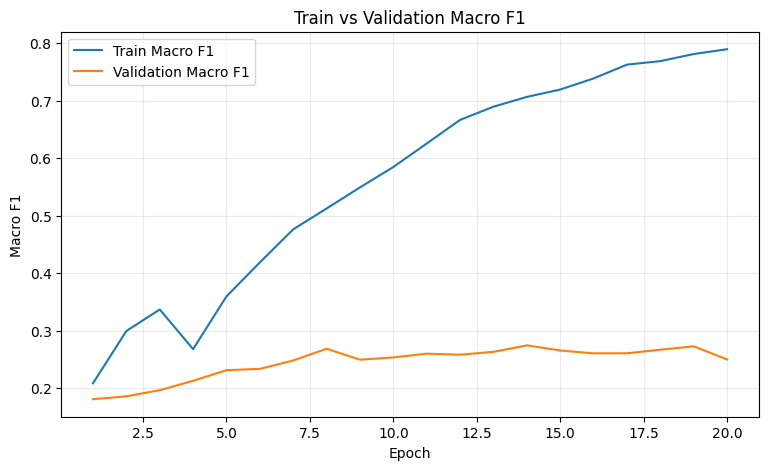

In [22]:
# ============================================================
# 21. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(
    history
)

HISTORY_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_training_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False,
)

display(
    history_df.tail(15)
)

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1",
)

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1",
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title(
    "Train vs Validation Macro F1"
)
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 22. Load Best Model dan Tune Confidence menggunakan Validation

Confidence threshold **tidak** dipilih dari official test.

In [23]:
# ============================================================
# 22. LOAD BEST + VALIDATION CALIBRATION
# ============================================================

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
)

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

BEST_ALPHA = float(
    checkpoint["alpha"]
)

BEST_BETA = float(
    checkpoint["beta"]
)

val_outputs = collect_outputs(
    model,
    val_loader,
)

val_score = (
    fused_scores_from_logits(
        val_outputs["joint_logits"],
        val_outputs["season_logits"],
        val_outputs["subtype_logits"],
        BEST_ALPHA,
        BEST_BETA,
    )
)

# Temperature scaling for fused score
val_score_tensor = torch.tensor(
    val_score,
    dtype=torch.float32,
)

val_y_tensor = torch.tensor(
    val_outputs["y_joint"],
    dtype=torch.long,
)

log_temperature = torch.nn.Parameter(
    torch.zeros(1)
)

optimizer_t = torch.optim.LBFGS(
    [log_temperature],
    lr=0.05,
    max_iter=50,
)

nll = nn.CrossEntropyLoss()


def temp_closure():
    optimizer_t.zero_grad()

    temperature = (
        torch.exp(
            log_temperature
        )
        .clamp(
            0.05,
            20.0,
        )
    )

    loss = nll(
        val_score_tensor
        / temperature,
        val_y_tensor,
    )

    loss.backward()

    return loss


optimizer_t.step(
    temp_closure
)

TEMPERATURE = float(
    torch.exp(
        log_temperature.detach()
    )
    .clamp(
        0.05,
        20.0,
    )
    .item()
)

val_probs_cal = np_softmax(
    val_score
    / TEMPERATURE
)

val_pred = val_probs_cal.argmax(
    axis=1
)

val_conf = val_probs_cal.max(
    axis=1
)

print(
    "Fusion alpha:",
    BEST_ALPHA
)

print(
    "Fusion beta :",
    BEST_BETA
)

print(
    "Temperature :",
    round(
        TEMPERATURE,
        4,
    )
)

Fusion alpha: 0.75
Fusion beta : 0.0
Temperature : 2.4078


In [24]:
# ============================================================
# 23. CHOOSE PLATFORM CONFIDENCE THRESHOLD ON VALIDATION
# ============================================================

def choose_selective_threshold(
    probs,
    y_true,
    target_accuracy,
    min_coverage,
):
    pred = probs.argmax(
        axis=1
    )

    conf = probs.max(
        axis=1
    )

    rows = []

    for threshold in np.arange(
        0.20,
        0.91,
        0.01,
    ):
        mask = (
            conf >= threshold
        )

        coverage = (
            mask.mean()
        )

        if mask.sum() == 0:
            continue

        acc = accuracy_score(
            y_true[mask],
            pred[mask],
        )

        rows.append({
            "threshold": float(
                threshold
            ),
            "coverage": float(
                coverage
            ),
            "selective_accuracy": float(
                acc
            ),
        })

    table = pd.DataFrame(
        rows
    )

    valid = table[
        (
            table[
                "selective_accuracy"
            ]
            >= target_accuracy
        )
        & (
            table["coverage"]
            >= min_coverage
        )
    ]

    if len(valid):
        best = (
            valid
            .sort_values(
                [
                    "coverage",
                    "selective_accuracy",
                ],
                ascending=[
                    False,
                    False,
                ],
            )
            .iloc[0]
        )

        reason = (
            "target_accuracy_met"
        )

    else:
        # Fallback: balanced utility
        table["utility"] = (
            table[
                "selective_accuracy"
            ]
            * np.sqrt(
                table["coverage"]
            )
        )

        best = (
            table
            .sort_values(
                "utility",
                ascending=False,
            )
            .iloc[0]
        )

        reason = (
            "fallback_best_utility"
        )

    return (
        float(
            best["threshold"]
        ),
        table,
        reason,
    )


(
    CONFIDENCE_THRESHOLD,
    threshold_table,
    threshold_reason,
) = choose_selective_threshold(
    val_probs_cal,
    val_outputs["y_joint"],
    TARGET_SELECTIVE_ACCURACY,
    MIN_SELECTIVE_COVERAGE,
)

print(
    "Confidence threshold:",
    round(
        CONFIDENCE_THRESHOLD,
        3,
    )
)

print(
    "Selection reason:",
    threshold_reason
)

display(
    threshold_table.tail(15)
)

Confidence threshold: 0.2
Selection reason: fallback_best_utility


,threshold,coverage,selective_accuracy,utility
42,0.62,0.012862,0.500000,0.056705
43,0.63,0.009646,0.333333,0.032739
44,0.64,0.009646,0.333333,0.032739
45,0.65,0.006431,0.000000,0.000000
46,0.66,0.006431,0.000000,0.000000
47,0.67,0.003215,0.000000,0.000000
48,0.68,0.003215,0.000000,0.000000
49,0.69,0.003215,0.000000,0.000000
50,0.70,0.003215,0.000000,0.000000
51,0.71,0.003215,0.000000,0.000000


## 24. Official Test — Final Evaluation

Official test dipakai **sekali** setelah semua keputusan:
- checkpoint,
- fusion alpha/beta,
- temperature,
- confidence threshold

sudah dipilih dari validation.

In [25]:
# ============================================================
# 24. OFFICIAL TEST
# ============================================================

test_outputs = collect_outputs(
    model,
    test_loader,
)

test_score = (
    fused_scores_from_logits(
        test_outputs["joint_logits"],
        test_outputs["season_logits"],
        test_outputs["subtype_logits"],
        BEST_ALPHA,
        BEST_BETA,
    )
)

test_probs = np_softmax(
    test_score
    / TEMPERATURE
)

y_true = test_outputs[
    "y_joint"
]

y_pred = test_probs.argmax(
    axis=1
)

test_metrics = macro_metrics(
    y_true,
    y_pred,
)

_, _, weighted_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0,
    )
)

top3_idx = np.argsort(
    test_probs,
    axis=1,
)[:, -3:]

top3_accuracy = float(
    np.mean([
        true in row
        for true, row
        in zip(
            y_true,
            top3_idx,
        )
    ])
)

# Derived season performance from final joint output
season_true = np.array([
    JOINT_TO_SEASON[i]
    for i in y_true
])

season_pred = np.array([
    JOINT_TO_SEASON[i]
    for i in y_pred
])

derived_season_accuracy = (
    accuracy_score(
        season_true,
        season_pred,
    )
)

# Selective / confidence-aware performance
test_conf = test_probs.max(
    axis=1
)

accepted = (
    test_conf
    >= CONFIDENCE_THRESHOLD
)

selective_coverage = float(
    accepted.mean()
)

if accepted.sum() > 0:
    selective_accuracy = float(
        accuracy_score(
            y_true[accepted],
            y_pred[accepted],
        )
    )
else:
    selective_accuracy = None

final_metrics = {
    **test_metrics,
    "weighted_f1": float(
        weighted_f1
    ),
    "top3_accuracy": (
        top3_accuracy
    ),
    "derived_season_accuracy": float(
        derived_season_accuracy
    ),
    "selective_coverage": (
        selective_coverage
    ),
    "selective_accuracy": (
        selective_accuracy
    ),
    "confidence_threshold": (
        CONFIDENCE_THRESHOLD
    ),
    "temperature": TEMPERATURE,
    "fusion_alpha": BEST_ALPHA,
    "fusion_beta": BEST_BETA,
}

print("=" * 72)
print("OFFICIAL TEST RESULTS")
print("=" * 72)

for key, value in (
    final_metrics.items()
):
    if isinstance(
        value,
        (int, float),
    ) and value is not None:
        print(
            f"{key:28s}: "
            f"{value:.4f}"
        )
    else:
        print(
            f"{key:28s}: "
            f"{value}"
        )

OFFICIAL TEST RESULTS
accuracy                    : 0.2862
macro_precision             : 0.2599
macro_recall                : 0.2629
macro_f1                    : 0.2585
weighted_f1                 : 0.2803
top3_accuracy               : 0.6217
derived_season_accuracy     : 0.5099
selective_coverage          : 0.8805
selective_accuracy          : 0.3051
confidence_threshold        : 0.2000
temperature                 : 2.4078
fusion_alpha                : 0.7500
fusion_beta                 : 0.0000


In [26]:
# ============================================================
# 25. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    y_true,
    y_pred,
    target_names=joint_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(
    report
).T

display(
    report_df.loc[
        joint_names,
        [
            "precision",
            "recall",
            "f1-score",
            "support",
        ],
    ].sort_values(
        "recall",
        ascending=False,
    )
)

REPORT_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_classification_report.csv"
)

report_df.to_csv(
    REPORT_PATH
)

,precision,recall,f1-score,support
inverno_deep,0.419118,0.487179,0.450593,117.0
autunno_deep,0.413462,0.383929,0.398148,112.0
primavera_warm,0.325000,0.356164,0.339869,73.0
inverno_cool,0.298077,0.348315,0.321244,89.0
estate_light,0.323529,0.314286,0.318841,70.0
autunno_warm,0.285714,0.297297,0.291391,74.0
primavera_light,0.219512,0.281250,0.246575,64.0
inverno_bright,0.326087,0.258621,0.288462,58.0
estate_cool,0.134328,0.169811,0.150000,53.0
autunno_soft,0.159420,0.150685,0.154930,73.0


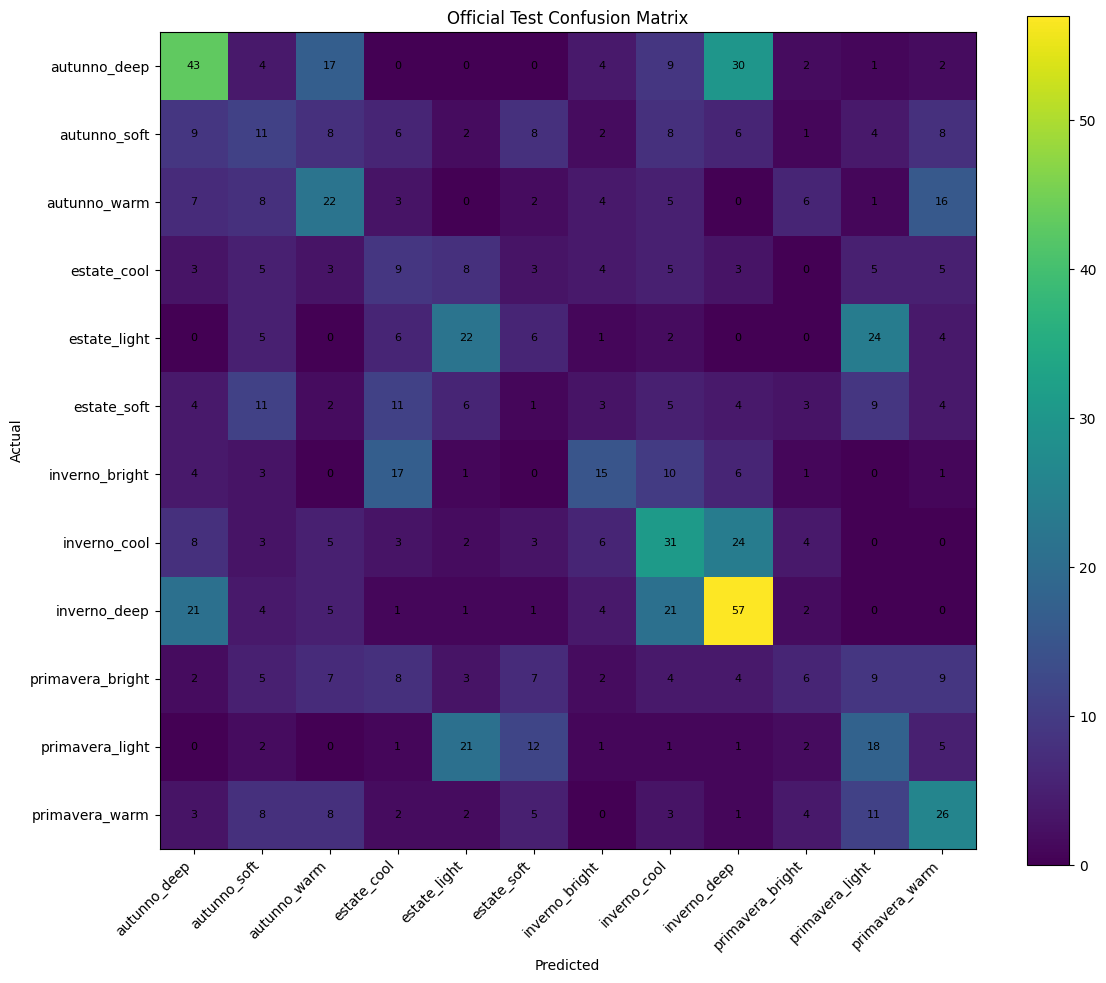

In [27]:
# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(
        range(
            len(joint_names)
        )
    ),
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(
        len(joint_names)
    )
)

ax.set_yticks(
    np.arange(
        len(joint_names)
    )
)

ax.set_xticklabels(
    joint_names,
    rotation=45,
    ha="right",
)

ax.set_yticklabels(
    joint_names
)

ax.set_xlabel(
    "Predicted"
)

ax.set_ylabel(
    "Actual"
)

ax.set_title(
    "Official Test Confusion Matrix"
)

for i in range(
    len(joint_names)
):
    for j in range(
        len(joint_names)
    ):
        ax.text(
            j,
            i,
            str(
                cm[i, j]
            ),
            ha="center",
            va="center",
            fontsize=8,
        )

fig.colorbar(
    im,
    ax=ax,
)

plt.tight_layout()

CM_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_confusion_matrix.png"
)

plt.savefig(
    CM_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

## 27. Benchmark Comparison

Benchmark pembanding yang digunakan dalam project:
- baseline run sebelumnya: Accuracy 29.28%, Macro F1 25.54%, Top-3 62.72%
- benchmark paper FaRL16 12-class: Accuracy 31.8%, F1 31.0%, Top-3 66.3%

In [28]:
# ============================================================
# 27. BENCHMARK COMPARISON
# ============================================================

benchmarks = pd.DataFrame([
    {
        "model": "Previous EfficientNet-B0",
        "accuracy": 0.2928,
        "macro_f1": 0.2554,
        "top3": 0.6272,
    },
    {
        "model": "FaRL16 paper benchmark",
        "accuracy": 0.3180,
        "macro_f1": 0.3100,
        "top3": 0.6630,
    },
    {
        "model": EXPERIMENT_ID,
        "accuracy": final_metrics["accuracy"],
        "macro_f1": final_metrics["macro_f1"],
        "top3": final_metrics["top3_accuracy"],
    },
])

display(benchmarks)

print(
    "Δ accuracy vs previous:",
    round(
        (
            final_metrics["accuracy"]
            - 0.2928
        ) * 100,
        2,
    ),
    "pp",
)

print(
    "Δ accuracy vs FaRL16:",
    round(
        (
            final_metrics["accuracy"]
            - 0.3180
        ) * 100,
        2,
    ),
    "pp",
)

,model,accuracy,macro_f1,top3
0,Previous EfficientNet-B0,0.292800,0.255400,0.627200
1,FaRL16 paper benchmark,0.318000,0.310000,0.663000
2,E4_HIER_MT,0.286184,0.258482,0.621711


Δ accuracy vs previous: -0.66 pp
Δ accuracy vs FaRL16: -3.18 pp


## 28. Platform Inference Function

**Input fungsi di bawah adalah RGB-M / masked RGB image.**

Platform final harus:
1. validasi kualitas foto,
2. melakukan face parsing/masking yang konsisten,
3. mengirim masked RGB ke fungsi ini,
4. memakai confidence gate.

Jika `status="uncertain"`, jangan paksa satu palette sebagai kebenaran. Tampilkan Top-3 atau minta foto ulang di pencahayaan netral.

In [29]:
# ============================================================
# 28. PLATFORM INFERENCE
# ============================================================

def predict_rgbm_pil(
    pil_image,
    model=model,
    top_k=3,
):
    model.eval()

    image_tensor = (
        eval_transform(
            pil_image.convert("RGB")
        )
        .unsqueeze(0)
        .to(DEVICE)
    )

    with torch.no_grad():
        outputs = model(
            image_tensor
        )

    joint_logits = (
        outputs["joint"]
        .float()
        .cpu()
        .numpy()
    )

    season_logits = (
        outputs["season"]
        .float()
        .cpu()
        .numpy()
    )

    subtype_logits = (
        outputs["subtype"]
        .float()
        .cpu()
        .numpy()
    )

    score = (
        fused_scores_from_logits(
            joint_logits,
            season_logits,
            subtype_logits,
            BEST_ALPHA,
            BEST_BETA,
        )
    )

    probs = np_softmax(
        score
        / TEMPERATURE
    )[0]

    order = np.argsort(
        probs
    )[::-1]

    top = []

    for idx in order[:top_k]:
        joint_name = (
            joint_names[idx]
        )

        season, subtype = (
            joint_name.split(
                "_",
                1,
            )
        )

        top.append({
            "joint_class": joint_name,
            "season": season,
            "subtype": subtype,
            "probability": float(
                probs[idx]
            ),
        })

    confidence = float(
        probs[
            order[0]
        ]
    )

    margin = float(
        probs[order[0]]
        - probs[order[1]]
    )

    status = (
        "confident"
        if confidence
        >= CONFIDENCE_THRESHOLD
        else "uncertain"
    )

    return {
        "status": status,
        "confidence": confidence,
        "margin_top1_top2": margin,
        "threshold": (
            CONFIDENCE_THRESHOLD
        ),
        "prediction": top[0],
        "top_k": top,
        "input_requirement": (
            "RGB-M / masked face image"
        ),
    }

In [30]:
# ============================================================
# 29. SAVE DEPLOYMENT ARTIFACTS
# ============================================================

FINAL_METRICS_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_final_metrics.json"
)

DEPLOYMENT_CONFIG_PATH = Path(
    f"/kaggle/working/"
    f"{EXPERIMENT_ID}_deployment_config.json"
)

with open(
    FINAL_METRICS_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_metrics,
        f,
        indent=2,
    )

deployment_config = {
    "experiment_id": EXPERIMENT_ID,
    "model": "EfficientNet-B0 hierarchical multi-task",
    "main_output": "12 joint classes",
    "auxiliary_outputs": [
        "4 seasons",
        "6 subtype names",
    ],
    "joint_names": joint_names,
    "season_names": season_names,
    "subtype_names": subtype_names,
    "joint_to_season_idx": joint_to_season_idx,
    "joint_to_subtype_idx": joint_to_subtype_idx,
    "img_size": IMG_SIZE,
    "normalization_mean": NORM_MEAN,
    "normalization_std": NORM_STD,
    "fusion_alpha": BEST_ALPHA,
    "fusion_beta": BEST_BETA,
    "temperature": TEMPERATURE,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "input_requirement": "RGB-M masked face",
    "uncertain_action": (
        "show Top-3 or request a new photo"
    ),
}

with open(
    DEPLOYMENT_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        deployment_config,
        f,
        indent=2,
    )

print("Artifacts:")
for p in [
    BEST_MODEL_PATH,
    HISTORY_PATH,
    REPORT_PATH,
    CM_PATH,
    FINAL_METRICS_PATH,
    DEPLOYMENT_CONFIG_PATH,
]:
    print("-", p)

print(
    "\n✅ Hierarchical multi-task experiment completed."
)

Artifacts:
- /kaggle/working/E4_HIER_MT_best_model.pth
- /kaggle/working/E4_HIER_MT_training_history.csv
- /kaggle/working/E4_HIER_MT_classification_report.csv
- /kaggle/working/E4_HIER_MT_confusion_matrix.png
- /kaggle/working/E4_HIER_MT_final_metrics.json
- /kaggle/working/E4_HIER_MT_deployment_config.json

✅ Hierarchical multi-task experiment completed.


# Interpretasi Kelayakan Platform

Jangan menilai kelayakan platform dari train accuracy.

Prioritas:
1. **Official Test Macro F1 / Accuracy**
2. Recall kelas-kelas lemah
3. Top-3 Accuracy
4. Selective Accuracy + Coverage

Contoh interpretasi:
- Top-1 masih rendah tetapi selective accuracy tinggi → platform dapat memakai **confidence gate**.
- Confidence rendah → Top-3 + retake flow.
- Jika official accuracy tetap sekitar 30% dan selective coverage terlalu kecil, model belum layak untuk memberikan satu rekomendasi final tanpa mekanisme uncertainty.

Model terbaik untuk produk adalah model yang **tahu kapan ia tidak yakin**, bukan model yang selalu memaksa satu label.

In [31]:
import modellab_registry

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook di sel sebelumnya
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals() dan panggil variabel konfigurasi master
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="EfficientNet-B0",
    objective="Meningkatkan model CNN dengan Hierarchical Multitask",
    dataset="deep_armocromia",
    owner="Fatih Itsbatul Haq"
)

===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "EfficientNet-B0", "objective": "Meningkatkan model CNN dengan Hierarchical Multitask", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.28618421052631576, "f1": 0.2584817468907255, "precision": 0.2598857771845085, "recall": 0.2628599257660944}}
===REGISTRY_PAYLOAD_END===
